# Objetivo del análisis

El objetivo de este análisis es estudiar la distribución de las edades de los estudiantes matriculados en instituciones de educación superior de la Región de Tarapacá durante el año 2021, considerando el tipo de institución.

Para realizar el análisis se utilizarán las siguientes variables:

* **Variable cualitativa:** `TIPO DE INSTITUCION`
* **Variable cuantitativa:** `EDAD`

A partir de estas variables se busca describir y comparar la distribución de las edades según el tipo de institución, utilizando tablas de frecuencia, gráficos y medidas estadísticas de posición y dispersión.


# Exploración de datos

In [59]:
import pandas as pd
import math
import matplotlib.pyplot as plt

df = pd.read_excel("02_MATRICULAS_ED_SUPERIOR_TARAPACA_2021.xlsx")

## Exploración inicial de los datos

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15459 entries, 0 to 15458
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   ID                                       15459 non-null  int64  
 1   GENERO                                   15459 non-null  str    
 2   EDAD                                     15459 non-null  int64  
 3   RANGO EDAD                               15459 non-null  str    
 4   AÑO INGRESO                              15459 non-null  int64  
 5   SEMESTRE INGRESO                         15459 non-null  str    
 6   TIPO DE INSTITUCION                      15459 non-null  str    
 7   NOMBRE DE INSTITUCION                    15459 non-null  str    
 8   ACREDITACION INSTITUCIONAL               15459 non-null  str    
 9   PERIODO DE ACREDITACION                  14066 non-null  str    
 10  AÑOS DE ACREDITACION                     14066 non-null  

In [ ]:
df.shape

(15459, 28)

In [ ]:
df.columns

## Registro de estudiante por cada tipo de Instutucion 

In [6]:
df["TIPO DE INSTITUCION"].value_counts()

TIPO DE INSTITUCION
Universidades CRUCH             6644
Institutos Profesionales        3118
Centros de Formacion Tecnica    3115
Universidades Privadas          2582
Name: count, dtype: int64

## Resumen estadístico de la variable cuantitativa `Edad`

In [62]:
df["EDAD"].describe()

count    15459.000000
mean        25.963128
std          7.408592
min         17.000000
25%         21.000000
50%         24.000000
75%         29.000000
max         74.000000
Name: EDAD, dtype: float64

## Frecuencia absoluta de la variable `Edad`

In [63]:
frecuencia = df["EDAD"].value_counts().sort_index()
frecuencia

EDAD
17       2
18     380
19    2024
20     826
21    1630
22    1515
23    1257
24    1578
25     371
26     727
27     563
28     511
29     639
30     170
31     353
32     319
33     324
34     406
35      92
36     196
37     188
38     184
39     209
40      65
41     137
42     102
43      92
44      70
45      80
46      61
47      66
48      66
49      33
50      53
51      29
52      25
53      24
54      18
55      16
56       9
57      14
58       9
59       7
60       3
61       5
62       3
63       2
64       1
65       1
69       1
70       1
73       1
74       1
Name: count, dtype: int64

## Tabla de frecuencias de la la variable `EDAD`

In [65]:
tabla_frecuencia = pd.DataFrame({
    "Frecuencia absoluta (fi)": frecuencia,
    "Frecuencia acumulada (Fi)": frecuencia.cumsum(),
    "Frecuencia relativa % (hi)": frecuencia / frecuencia.sum()*100,
    "Frecuencia relativa acumulada % (Hi)": (frecuencia / frecuencia.sum()).cumsum()*100
})

tabla_frecuencia.round(2)

,Frecuencia absoluta (fi),Frecuencia acumulada (Fi),Frecuencia relativa % (hi),Frecuencia relativa acumulada % (Hi)
EDAD,,,,
17,2,2,0.01,0.01
18,380,382,2.46,2.47
19,2024,2406,13.09,15.56
20,826,3232,5.34,20.91
21,1630,4862,10.54,31.45
22,1515,6377,9.80,41.25
23,1257,7634,8.13,49.38
24,1578,9212,10.21,59.59
25,371,9583,2.40,61.99


## Calcular el intervalo construir un grafico por rango de edad.

In [46]:
muestra = df["EDAD"].count()
intervalos = round(1 + 3.322 * math.log10(muestra))

print("Muestra:", muestra)
print("Número de intervalos:", intervalos)

Muestra: 15459
Número de intervalos: 15


In [48]:
df["Intervalos_edad"] = pd.cut(
    df["EDAD"],
    bins=intervalos,
    include_lowest=True,
    precision=2
)

cuenta_intervalos_edad = df.groupby(
    "Intervalos_edad",
    observed=True
).size()

## Grafico representativo de la variable `Edad`

In [ ]:
tabla_frecuencia_edad = pd.DataFrame({
    "Frecuencia absoluta": cuenta_intervalos_edad,
    "Frecuencia absoluta acumulada": cuenta_intervalos_edad.cumsum(),
    "Frecuencia relativa (%)": cuenta_intervalos_edad / muestra * 100,
    "Frecuencia relativa acumulada (%)":
        (round(cuenta_intervalos_edad / muestra * 100).cumsum())
})

round(tabla_frecuencia_edad, 1)

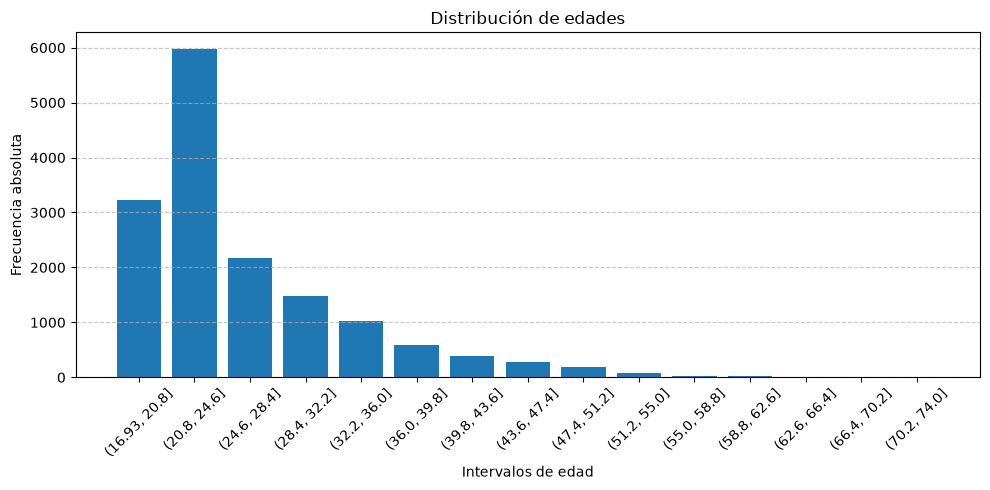

In [57]:
plt.figure(figsize=(10, 5))

plt.bar(
    cuenta_intervalos_edad.index.astype(str),
    cuenta_intervalos_edad
)

plt.xlabel("Intervalos de edad")
plt.ylabel("Frecuencia absoluta")
plt.title("Distribución de edades")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Ver los datos extremos para interpretar el grafico

In [42]:
print("Intervalo con mayor frecuencia:")
print(cuenta_intervalos_edad.idxmax())

print("Frecuencia:")
print(cuenta_intervalos_edad.max())

print("\nIntervalo con menor frecuencia:")
print(cuenta_intervalos_edad.idxmin())

print("Frecuencia:")
print(cuenta_intervalos_edad.min())

Intervalo con mayor frecuencia:
(20.8, 24.6]
Frecuencia:
5980

Intervalo con menor frecuencia:
(66.4, 70.2]
Frecuencia:
2


#### Intepretacion

La distribución de las edades se encuentra agrupada en 15 intervalos. El intervalo con mayor frecuencia es **(20,8; 24,6]**, con **5.980 estudiantes**, concentrando la mayor cantidad de estudiantes de la muestra.

Por otro lado, el intervalo con menor frecuencia es **(66,4; 70,2]**, con solo **2 estudiantes**. Esto indica que la muestra está principalmente concentrada en edades jóvenes, mientras que las edades más altas presentan una frecuencia considerablemente menor.
